# Previsão diária de bicicletas

A pergunta é simples: usando apenas o histórico até certa data, quão bem conseguimos prever os dias seguintes? O código do experimento está em [forecast.py](forecast.py). Aqui mostro a divisão dos dados, a escolha do modelo e onde ele erra.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from forecast import DATA_URL, preparar_dados, dividir, experimento

serie, dias_excluidos = preparar_dados(pd.read_csv(DATA_URL))
desenvolvimento, validacao, treino, teste = dividir(serie)
print(f"{len(serie)} dias completos; {dias_excluidos} incompletos fora da modelagem")
display(pd.DataFrame({
    "parte": ["Desenvolvimento", "Validação", "Teste reservado"],
    "dias": [len(desenvolvimento), len(validacao), len(teste)],
    "início": [x.ds.min().date() for x in (desenvolvimento, validacao, teste)],
    "fim": [x.ds.max().date() for x in (desenvolvimento, validacao, teste)],
}))

696 dias completos; 34 incompletos fora da modelagem


,parte,dias,início,fim
0,Desenvolvimento,466,2015-01-04,2016-05-07
1,Validação,90,2016-05-08,2016-08-09
2,Teste reservado,140,2016-08-10,2017-01-03


## Regras de comparação

O teste são os 20% finais dos dias completos. Separo os últimos 90 dias do trecho anterior para escolher o método. Duas referências não usam valores futuros: a mais simples repete o último valor observado para cada dia da semana; a **sazonal** recupera o mesmo dia da semana de 52 semanas antes. Se esse dia foi excluído como incompleto, a referência sazonal recua ao último valor conhecido daquele dia da semana.

As outras opções são Prophet padrão, Prophet com sazonalidade anual e a mesma configuração após remover observações fora do intervalo ajustado **somente no treino**. A menor RMSE na validação decide o modelo. Remover picos não é automaticamente uma melhoria: eles podem ser demanda legítima.

## Como a referência prevê os 90 dias de validação

Ela guarda o último valor observado de cada dia da semana no desenvolvimento e repete esses sete valores ao longo do horizonte. Mostrar alguns pares entre observado e previsto ajuda a entender por que esta é uma referência deliberadamente simples.

In [2]:
from forecast import prever, pontuar
import numpy as np

prev_semana, _ = prever("ultimo_dia_semana", desenvolvimento, validacao)
amostra_validacao = validacao[["ds", "y"]].head(7).copy()
amostra_validacao["referencia"] = prev_semana[:7]
display(amostra_validacao)

,ds,y,referencia
466,2016-05-08,44758,29249
467,2016-05-09,30507,19428
468,2016-05-10,21452,31962
469,2016-05-11,27574,36182
470,2016-05-12,38082,38684
471,2016-05-13,34706,39589
472,2016-05-14,30046,43819


In [3]:
validacao_modelos, final = experimento(serie)
display(validacao_modelos.round(2))
print("Escolhido pela validação:", final["modelo"])

,modelo,RMSE,MAE,WAPE,outliers_removidos_no_ajuste
0,prophet_anual,6605.41,5199.87,0.15,0
1,prophet_anual_sem_outliers,6609.79,5128.42,0.15,54
2,prophet_padrao,6992.02,5798.12,0.17,0
3,ano_anterior_52_semanas,9133.07,6640.89,0.20,0
4,ultimo_dia_semana,9549.77,7544.33,0.22,0


Escolhido pela validação: prophet_anual


## O comportamento na validação

A tabela anterior decide o vencedor. Para ver além do RMSE, comparo o Prophet anual com as duas referências e a demanda observada no mesmo período de validação. Nenhum valor do teste entra neste gráfico.

RMSE do anual na validação: 6605.41


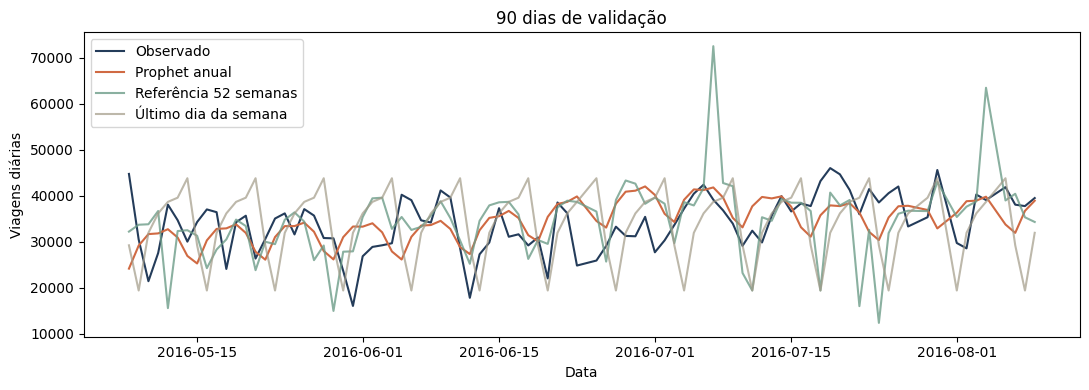

In [4]:
prev_anual, _ = prever("prophet_anual", desenvolvimento, validacao)
prev_ano_anterior, _ = prever("ano_anterior_52_semanas", desenvolvimento, validacao)
print("RMSE do anual na validação:", round(pontuar(validacao["y"], prev_anual)["RMSE"], 2))
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(validacao["ds"], validacao["y"], label="Observado", color="#243c5a")
ax.plot(validacao["ds"], prev_anual, label="Prophet anual", color="#d06a43")
ax.plot(validacao["ds"], prev_ano_anterior, label="Referência 52 semanas", color="#6d9c88", alpha=0.8)
ax.plot(validacao["ds"], prev_semana, label="Último dia da semana", color="#a19a87", alpha=0.7)
ax.set(title="90 dias de validação", xlabel="Data", ylabel="Viagens diárias")
ax.legend()
fig.tight_layout()
plt.show()

A remoção de outliers descartou 54 observações do ajuste, mas ficou ligeiramente atrás do Prophet anual na validação: RMSE de 6.609,79 contra 6.605,41. Por isso não a chamei de melhoria nem a escolhi pelo resultado do teste.

## Três datas de corte antes do teste

O período de teste continua intocado. Para verificar se a escolha não depende só da validação mais recente, repito previsões de 90 **dias completos** em três cortes anteriores ao teste. Em cada rodada, o modelo vê apenas datas anteriores à sua janela. As janelas se sobrepõem, então não são três testes independentes.

In [5]:
from forecast import validacao_historica

diagnostico = validacao_historica(serie)
comparacao_cortes = diagnostico.pivot(index="corte", columns="modelo", values="RMSE")
display(comparacao_cortes.round(0))
print("WAPE por corte (proporção da demanda observada):")
display(diagnostico.pivot(index="corte", columns="modelo", values="WAPE").round(3))

modelo,ano_anterior_52_semanas,prophet_anual,prophet_anual_sem_outliers,prophet_padrao,ultimo_dia_semana
corte,,,,,
2016-01-22,5202.0,4025.0,3963.0,12619.0,5062.0
2016-03-15,7110.0,6439.0,6780.0,13788.0,9593.0
2016-05-07,9133.0,6605.0,6610.0,6992.0,9550.0


WAPE por corte (proporção da demanda observada):


modelo,ano_anterior_52_semanas,prophet_anual,prophet_anual_sem_outliers,prophet_padrao,ultimo_dia_semana
corte,,,,,
2016-01-22,0.173,0.140,0.132,0.490,0.172
2016-03-15,0.193,0.168,0.172,0.417,0.278
2016-05-07,0.195,0.153,0.151,0.170,0.222


O Prophet anual teve RMSE menor que **as duas referências** nos três cortes. A referência de 52 semanas foi mais competitiva que a semanal fixa em dois dos três cortes. O Prophet padrão ficou pior que ambas nos dois primeiros. Retirar outliers ganhou em um corte, mas perdeu nos outros dois: o resultado não apoia tratar a remoção como melhoria garantida. Este diagnóstico não substitui o teste final nem comprova estabilidade em outros anos.

## Teste reservado

Depois de escolher o método, ele é ajustado novamente com todo o trecho anterior ao teste. Avalio **as duas referências** no mesmo período para dar escala ao erro, sem alterar a escolha feita na validação.

,modelo,RMSE,MAE,WAPE
0,prophet_anual,6160.98,4937.92,0.17
1,referência 52 semanas,8703.21,6274.19,0.22
2,referência semanal fixa,13849.16,11049.48,0.39


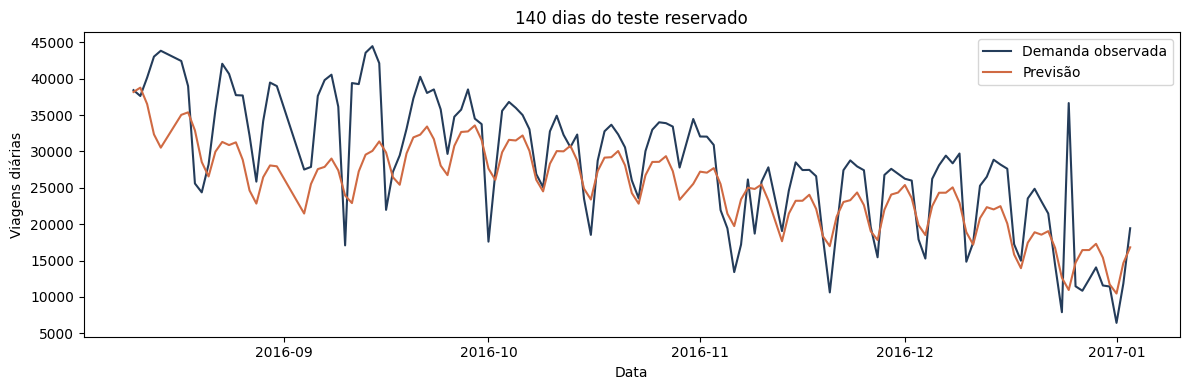

In [6]:
comparacao = pd.DataFrame([
    {"modelo": final["modelo"], **final["teste"]},
    {"modelo": "referência 52 semanas", **final["referencia_teste"]},
    {"modelo": "referência semanal fixa", **final["referencia_fixa_teste"]},
])
display(comparacao.round(2))
previsoes = final["previsoes"].copy()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(previsoes["ds"], previsoes["y"], label="Demanda observada", color="#243c5a")
ax.plot(previsoes["ds"], previsoes["yhat"], label="Previsão", color="#d06a43")
ax.set(title="140 dias do teste reservado", xlabel="Data", ylabel="Viagens diárias")
ax.legend()
fig.tight_layout()
plt.show()

## Erro ao longo do horizonte

O RMSE geral pode esconder semanas mais difíceis. Divido os 140 dias do teste em blocos consecutivos de 28 dias, preservando a ordem da previsão.

In [7]:
erros_horizonte = previsoes.copy()
erros_horizonte["bloco"] = np.arange(len(erros_horizonte)) // 28 + 1
erros_horizonte["erro_absoluto"] = (erros_horizonte["y"] - erros_horizonte["yhat"]).abs()
por_bloco = erros_horizonte.groupby("bloco").apply(
    lambda parte: pd.Series({"dias": len(parte), "MAE": parte["erro_absoluto"].mean(), "RMSE": np.sqrt(((parte["y"] - parte["yhat"]) ** 2).mean())}),
    include_groups=False,
)
display(por_bloco.round(2))

,dias,MAE,RMSE
bloco,,,
1,28.0,7485.69,8462.52
2,28.0,5433.82,6672.14
3,28.0,3809.78,4260.23
4,28.0,3238.08,3661.06
5,28.0,4722.25,6488.74


## Olhando os erros, não só a média

No teste, o Prophet anual obteve RMSE de **6.160,98** e WAPE de cerca de **17%**. A referência de 52 semanas obteve RMSE de **8.703,21** e WAPE de **22%**; a semanal fixa, RMSE de **13.849,16** e WAPE de **39%**. O gráfico ainda mostra trechos e picos que o modelo subestima. A tabela abaixo ajuda a localizar os maiores desvios antes de pensar em outras variáveis ou ajustes.

In [8]:
previsoes["erro"] = previsoes["y"] - previsoes["yhat"]
previsoes["erro_absoluto"] = previsoes["erro"].abs()
display(previsoes.nlargest(5, "erro_absoluto")[["ds", "y", "yhat", "erro"]].round(1))
print("Erro médio por dia da semana (positivo = subestimação):")
display(previsoes.groupby(previsoes["ds"].dt.day_name())["erro"].mean().round(0).sort_values(ascending=False))

,ds,y,yhat,erro
686,2016-12-25,36653,10945.0,25708.0
583,2016-09-11,39403,22896.9,16506.1
586,2016-09-14,44478,30075.1,14402.9
585,2016-09-13,43573,29558.3,14014.7
560,2016-08-14,43848,30519.2,13328.8


Erro médio por dia da semana (positivo = subestimação):


,erro
ds,
Wednesday,5182.0
Tuesday,5147.0
Monday,3358.0
Thursday,3293.0
Friday,2552.0
Sunday,2549.0
Saturday,-10.0


## O que ainda falta

As três janelas históricas se sobrepõem e cobrem apenas parte de dois anos; o teste reservado é um único período. O Prophet anual foi ajustado com menos de dois anos de histórico, condição em que a sazonalidade pode ser instável. Dias incompletos foram excluídos e isso pode mudar a amostra. A referência sazonal recorre à última observação do mesmo dia da semana quando a data de 52 semanas atrás está ausente. O próximo passo seria obter mais anos para repetir a avaliação. O procedimento de múltiplos cortes segue a ideia dos [diagnósticos do Prophet](https://facebook.github.io/prophet/docs/diagnostics.html).